<a href="https://colab.research.google.com/github/ismailkirac/dis-sagligi-sporcu-performansi/blob/main/Hafta6_Ogrenci_Proje_Veri_Analizi_Sablonu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6. Hafta | Kendi Projemin Veri Analizi — Ekip Teslim Şablonu

**Grup:** Diş Sağlığı ve Spor Grubu • **Proje:** Diş Sağlığının Sporcu Performansına Etkisi • **Ekip görevleri:** Veri simülasyonu, Pandas analizi, Matplotlib görselleştirmesi ve akademik raporlama.

Bu notebook başlangıç iskeletidir. Örnek dosya ve kodu kendi araştırma/proje verinize uyarlayın. **Veri uydurup gerçek ölçüm gibi sunmayın.**

## A. Veri tanıtımı
- **Veri setinin adı ve bağlantısı:** Sporcularda Diş Sağlığı Sorunları ve Haftalık Antrenman Kaybı (Temsili Veri Seti - Proje İçi Simülasyon)
- **Veri kaynağı / lisans / erişim tarihi:** 2026 Güz Dönemi Yazılım Mühendisliği Temelleri dersi proje çalışması kapsamında öğretim amaçlı üretilmiş temsili veridir / MIT Lisansı / 2026-11-08
- **CSV mi, JSON mu?:** CSV (`sporcu_dis_sagligi_verisi.csv`)
- **Satır ve sütunların anlamı:**
  - `sporcu_id`: Sporcunun kimlik kodu
  - `brans`: Sporcunun branşı (Futbol, Basketbol, Koşu, Yüzme vb.)
  - `dis_problemi_turu`: Karşılaşılan diş sağlığı sorunu (Çürük, Diş Sıkma / Bruksizm, Diş Eti İltihabı vb.)
  - `antrenman_kaybi_saat`: Problem nedeniyle haftalık kaybedilen antrenman süresi (saat)
  - `agri_skoru_1_10`: Sporcunun bildirdiği ağrı seviyesi (1-10 arası)
- **Ölçü birimi ve gözlem sayısı:** Saat ve skor puanı; toplam 6 gözlem
- **Gerçek mi / açık kaynak mı / temsili mi?:** Temsili veridir (öğretim ve konsept kanıtlama amaçlı üretilmiştir).
- **Ekip üyelerinin görevleri:** Veri tablosunun hazırlanması, eksik veri ve istatistik kontrolleri, sütun grafiklerinin oluşturulması, akademik yorumlama.

## B. Başlangıç: temsili veriyle çalışan örnek
Aşağıdaki örneği çalıştırın. Ardından **kendi dosyanızı** `veri_yolu` değişkeniyle gösterebilirsiniz.

In [6]:
from pathlib import Path
import pandas as pd

# Diş sağlığı ve sporcu performansı temsili veri seti
kayitlar = pd.DataFrame({
    "sporcu_id": ["SP-01", "SP-02", "SP-03", "SP-04", "SP-05", "SP-06"],
    "brans": ["Futbol", "Basketbol", "Koşu", "Yüzme", "Voleybol", "Bisiklet"],
    "dis_problemi_turu": [
        "Bruksizm (Diş Sıkma)",
        "Gingivit (Diş Eti)",
        "Derin Çürük",
        "Gömülü 20'lik",
        "Mine Erozyonu",
        "Diş Travması",
    ],
    "antrenman_kaybi_saat": [3.5, 2.0, 5.0, 6.5, 1.5, 4.0],
    "agri_skoru_1_10": [6, 4, 8, 9, 3, 7],
})

dosya_adi = "sporcu_dis_sagligi_verisi.csv"
kayitlar.to_csv(dosya_adi, index=False, encoding="utf-8-sig")

veri_yolu = dosya_adi
veri = pd.read_csv(veri_yolu)
print(veri)

  sporcu_id      brans     dis_problemi_turu  antrenman_kaybi_saat  \
0     SP-01     Futbol  Bruksizm (Diş Sıkma)                   3.5   
1     SP-02  Basketbol    Gingivit (Diş Eti)                   2.0   
2     SP-03       Koşu           Derin Çürük                   5.0   
3     SP-04      Yüzme         Gömülü 20'lik                   6.5   
4     SP-05   Voleybol         Mine Erozyonu                   1.5   
5     SP-06   Bisiklet          Diş Travması                   4.0   

   agri_skoru_1_10  
0                6  
1                4  
2                8  
3                9  
4                3  
5                7  


## C. Veri inceleme ve hesaplama
Kendi veri setinizi kullanırken sayısal sütun adlarını değiştirin. Sütun başlığında boşluk ve yazım farklarını kontrol edin.

In [7]:
print("Boyut (Satır, Sütun):", veri.shape)
print("\nEksik Veri Sayıları:\n", veri.isna().sum())
print("\nToplam Antrenman Kaybı (saat):", veri["antrenman_kaybi_saat"].sum())
print("Ortalama Antrenman Kaybı (saat):", round(veri["antrenman_kaybi_saat"].mean(), 2))
print("Ortalama Ağrı Skoru (1-10):", round(veri["agri_skoru_1_10"].mean(), 2))

Boyut (Satır, Sütun): (6, 5)

Eksik Veri Sayıları:
 sporcu_id               0
brans                   0
dis_problemi_turu       0
antrenman_kaybi_saat    0
agri_skoru_1_10         0
dtype: int64

Toplam Antrenman Kaybı (saat): 22.5
Ortalama Antrenman Kaybı (saat): 3.75
Ortalama Ağrı Skoru (1-10): 6.17


## D. Grafik ve sonuç dosyaları
Grafiğin başlığını, eksenini ve ölçü birimini kendi verinize göre güncelleyin.

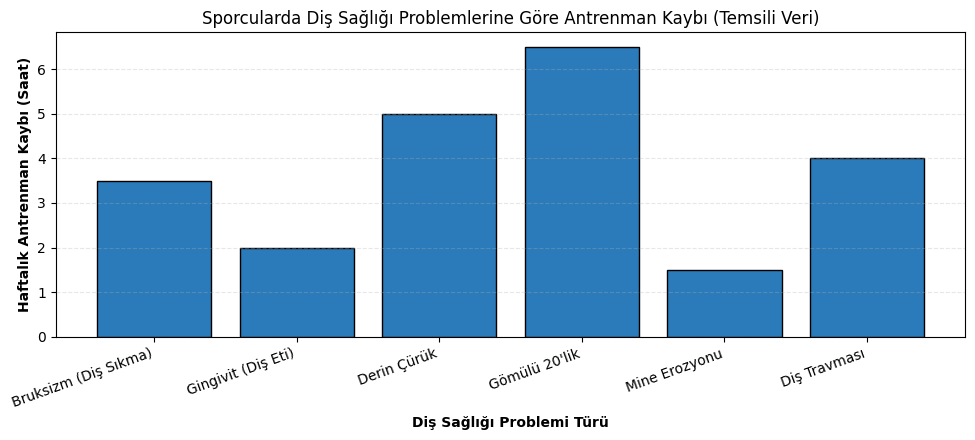

In [8]:
from pathlib import Path
import matplotlib.pyplot as plt

klasor = Path("sonuc")
klasor.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(
    veri["dis_problemi_turu"],
    veri["antrenman_kaybi_saat"],
    color="#2b7bba",
    edgecolor="black",
)
ax.set_xlabel("Diş Sağlığı Problemi Türü", fontweight="bold")
ax.set_ylabel("Haftalık Antrenman Kaybı (Saat)", fontweight="bold")
ax.set_title(
    "Sporcularda Diş Sağlığı Problemlerine Göre Antrenman Kaybı (Temsili Veri)",
    fontsize=12,
)
plt.xticks(rotation=20, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.3)

fig.tight_layout()
fig.savefig(klasor / "dis_sagligi_performans_kaybi.png", dpi=160)
veri.to_csv(klasor / "kullanilan_veri.csv", index=False, encoding="utf-8-sig")
plt.show()

## E. Akademik yorum
**Veri kaynağı ve değişken:** Bu çalışma, ağız ve diş sağlığı problemlerinin sporcuların haftalık antrenman sürekliliği ve ağrı düzeyleri üzerindeki olası etkisini incelemek üzere kurgulanmış temsili bir veri kümesidir. İncelenen ana değişkenler; sporcu branşı, diş problemi türü, antrenman kaybı süresi (saat) ve sübjektif ağrı skorudur (1-10).

**Toplam / ortalama ve birimler:** İncelenen 6 sporcuda haftalık toplam antrenman kaybı 22.5 saat, sporcu başına ortalama kayıp ise 3.75 saat olarak hesaplanmıştır. Sporcuların bildirdiği ortalama ağrı skoru 10 üzerinden 6.17 seviyesindedir.

**Grafikte görülen bulgu:** Akut müdahale ve cerrahi gerektiren problemlerin (gömülü 20'lik diş için 6.5 saat, derin çürük için 5.0 saat) sporcularda en yüksek antrenman kaybına yol açtığı görülmüştür. Bruksizm (diş sıkma) ve travma gibi durumlar da sırasıyla 3.5 ve 4.0 saatlik kayıpla sporcu performansını olumsuz etkilemektedir.

**Sınırlılıklar ve ölçemediği şeyler:** Veriler klinik ölçümlerden veya biyometrik performans takip cihazlarından (kalp ritmi değişkenliği, laktat eşiği vb.) elde edilmemiş olup öğretim amaçlı üretilmiş temsili bir simülasyondur. Sporcuların antrenman yoğunluğu, ağrı eşiği ve genel kondisyon durumları analize dahil edilmemiştir.

**Ekipçe yapılan işlem:** Veri seti Pandas DataFrame olarak yapılandırılmış, betimsel istatistikler ve kayıp süreleri hesaplanmış; Matplotlib kütüphanesi kullanılarak problem bazlı antrenman kaybını öne çıkaran sembollü sütun grafiği oluşturulmuş ve sonuç dosyaları dışa aktarılmıştır.

> Grafikte iki değişken birlikte görünse bile tek başına neden-sonuç kanıtı oluşmaz.

## F. Teslim kontrolü
- [x] Çalışır `.ipynb` dosyası
- [x] CSV/JSON örneği veya yasal ve erişilebilir veri kaynağı
- [x] Birim + veri kaynağı + lisans
- [x] En az 1 açıklamalı grafik 
- [x] Toplam ve ortalama hesabı
- [x] 4–5 cümlelik yorum
- [x] README içinde ekip katkıları
- [x] GitHub repo bağlantısı (https://github.com/ismailkirac/dis-sagligi-sporcu-performansi)
- [x] Gizli/kişisel veri ve anahtar bulunmuyor
